# Análise de Dados com Python — Módulo 1

**Pipeline:** Raw → Silver → Gold  
**Banco:** PostgreSQL  
**Execução:** VSCode + pgAdmin 4

Este notebook responde às sete perguntas de negócio da atividade. As consultas são executadas no PostgreSQL e os resultados são apresentados em tabelas e gráficos.

## 1. Conexão com o PostgreSQL

In [53]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import pandas as pd


def formatar_brl(valor):
    if pd.isna(valor):
        return ""
    parte_inteira, parte_decimal = f"{valor:,.2f}".split(".")
    return f"R${parte_inteira.replace(',', '.')},{parte_decimal}"


def formatar_eixo_brl(valor, _):
    return formatar_brl(valor)


# Permite importar config.py e banco.py quando o notebook é executado no VSCode.
PASTA_PROJETO = Path.cwd()
if str(PASTA_PROJETO) not in sys.path:
    sys.path.append(str(PASTA_PROJETO))

from banco import conectar

conexao = conectar()
print("Conexão PostgreSQL estabelecida com sucesso.")

Conexão PostgreSQL estabelecida com sucesso.


## 2. Pergunta 1 — Quais são os 5 órgãos com maior custo total?

O custo total é o campo calculado `valor_total` da camada Silver.

In [23]:
sql_q1 = """
SELECT
    nome_orgao_superior AS orgao,
    COUNT(*) AS quantidade_viagens,
    ROUND(SUM(valor_total), 2) AS custo_total
FROM silver_viagem
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5;
"""
df_q1 = pd.read_sql_query(sql_q1, conexao)
df_q1.assign(custo_total=df_q1["custo_total"].map(formatar_brl))

C:\Users\John\AppData\Local\Temp\ipykernel_21892\2630866659.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q1 = pd.read_sql_query(sql_q1, conexao)


,orgao,quantidade_viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,"R$486.933.121,65"
1,Ministério da Defesa,61912,"R$156.070.304,49"
2,Ministério da Educação,65295,"R$111.291.349,34"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"R$49.697.710,16"
4,Ministério da Previdência Social,8190,"R$40.417.309,06"


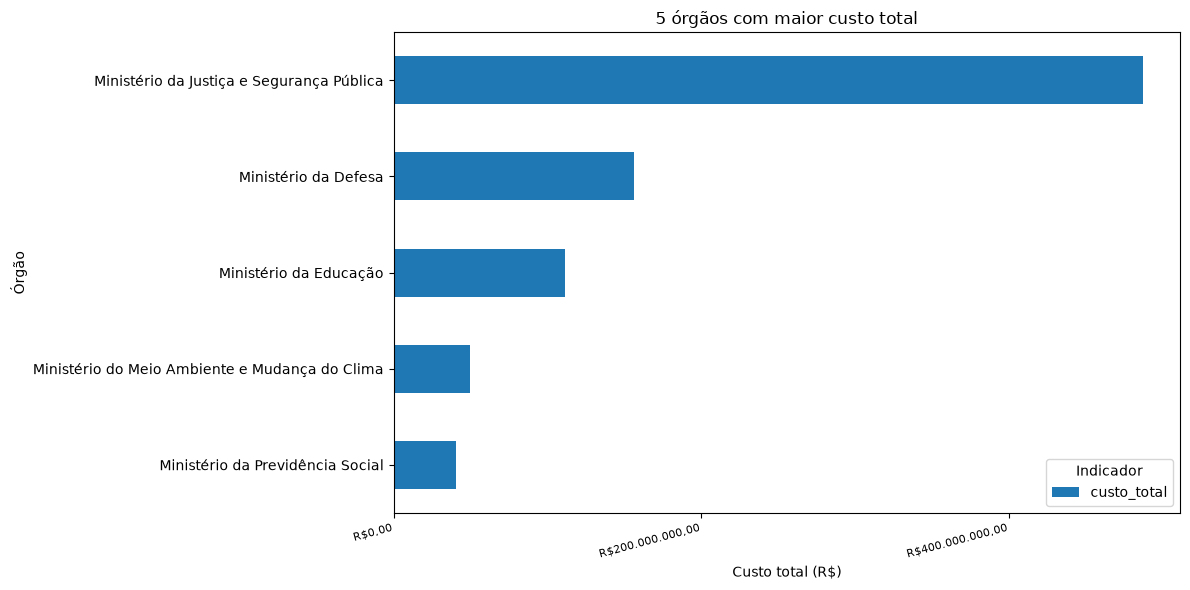

In [33]:
ax = df_q1.plot.barh(x="orgao", y="custo_total", legend=True, figsize=(12, 6))
ax.invert_yaxis()
ax.set_title("5 órgãos com maior custo total")
ax.legend(title="Indicador")
ax.set_xlabel("Custo total (R$)")
ax.set_ylabel("Órgão")
ax.xaxis.set_major_formatter(FuncFormatter(formatar_eixo_brl))
ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
ax.tick_params(axis="x", labelsize=8)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 3. Pergunta 2 — Quais são os 3 destinos com maior custo médio por viagem?

Para evitar contar duas vezes a mesma viagem quando ela possui mais de um trecho para o mesmo destino, a consulta considera cada par **viagem + destino** uma única vez antes de calcular a média.

In [24]:
sql_q2 = """
WITH destinos_unicos AS (
    SELECT DISTINCT
        id_viagem,
        destino_uf,
        destino_cidade
    FROM silver_trecho
    WHERE NULLIF(TRIM(destino_cidade), '') IS NOT NULL
),
base AS (
    SELECT
        d.destino_uf,
        d.destino_cidade,
        v.id_viagem,
        v.valor_total
    FROM destinos_unicos d
    JOIN silver_viagem v ON v.id_viagem = d.id_viagem
)
SELECT
    COALESCE(destino_uf, 'Exterior/Não informado') AS uf,
    destino_cidade AS destino,
    COUNT(DISTINCT id_viagem) AS viagens,
    ROUND(AVG(valor_total), 2) AS custo_medio_por_viagem
FROM base
GROUP BY destino_uf, destino_cidade
ORDER BY custo_medio_por_viagem DESC
LIMIT 3;
"""
df_q2 = pd.read_sql_query(sql_q2, conexao)
df_q2.assign(custo_medio_por_viagem=df_q2["custo_medio_por_viagem"].map(formatar_brl))

C:\Users\John\AppData\Local\Temp\ipykernel_21892\196243665.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q2 = pd.read_sql_query(sql_q2, conexao)


,uf,destino,viagens,custo_medio_por_viagem
0,São Paulo,Tejupá,1,"R$115.175,00"
1,São Paulo,Chavantes,1,"R$114.557,01"
2,Bahia,Teolândia,1,"R$109.322,50"


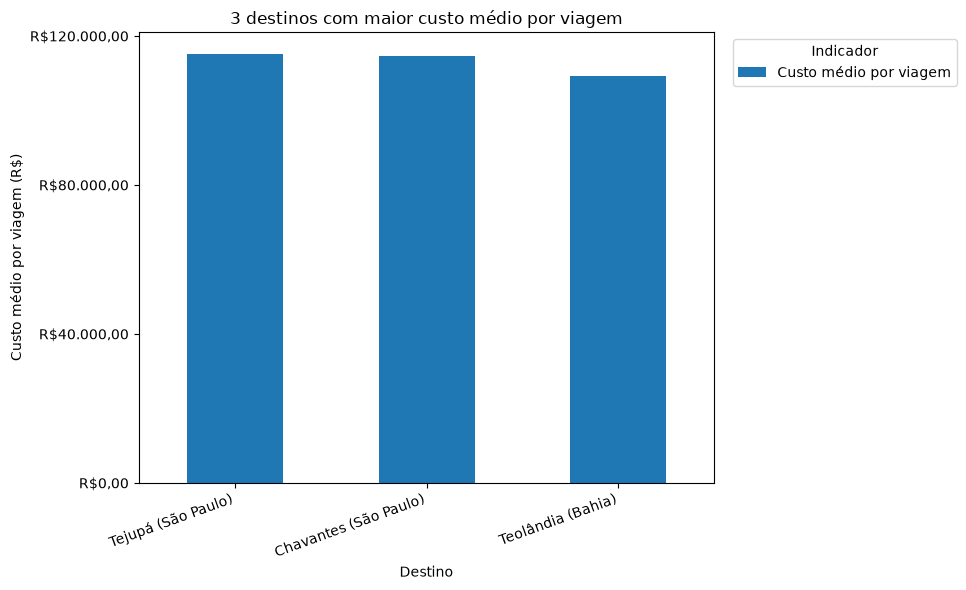

In [39]:
df_q2["rotulo"] = df_q2["destino"] + " (" + df_q2["uf"] + ")"
ax = df_q2.plot.bar(
    x="rotulo",
    y="custo_medio_por_viagem",
    label="Custo médio por viagem",
    figsize=(12, 6),
)
ax.set_title("3 destinos com maior custo médio por viagem")
ax.set_xlabel("Destino")
ax.set_ylabel("Custo médio por viagem (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_eixo_brl))
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.legend(title="Indicador", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=20, ha="right")
plt.tight_layout(rect=(0, 0, 0.82, 1))
plt.show()

## 4. Pergunta 3 — Qual foi a viagem de maior duração e qual seu custo total?

A tabela lista as cinco viagens de maior duração. A primeira linha responde diretamente à pergunta; o gráfico compara o custo total dessas cinco viagens.

In [46]:
sql_q3 = """
SELECT
    id_viagem,
    nome_viajante,
    nome_orgao_superior AS orgao,
    data_inicio,
    data_fim,
    duracao_dias,
    ROUND(valor_total, 2) AS custo_total,
    destinos
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC
LIMIT 5;
"""
df_q3 = pd.read_sql_query(sql_q3, conexao)
df_q3.assign(custo_total=df_q3["custo_total"].map(formatar_brl))

C:\Users\John\AppData\Local\Temp\ipykernel_21892\3932363299.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q3 = pd.read_sql_query(sql_q3, conexao)


,id_viagem,nome_viajante,orgao,data_inicio,data_fim,duracao_dias,custo_total,destinos
0,0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,Ministério da Previdência Social,2025-01-13,2026-01-31,383,"R$0,00",Mogi Mirim/SP
1,0000000000020793594,Informações protegidas por sigilo,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,378,"R$120.650,00",Informações protegidas por sigilo
2,0000000000020793492,Informações protegidas por sigilo,Ministério da Justiça e Segurança Pública,2025-01-11,2026-01-15,369,"R$113.382,50",Informações protegidas por sigilo
3,0000000000020774569,CLAUDIA ADRIANA DA SILVA,Ministério da Educação,2025-02-26,2026-03-02,369,"R$0,00",Bariloche/Argentina
4,0000000000020592696,RAILANA BERENICE AMORAS OLIVEIRA,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,366,"R$159.044,90","Brasília/DF, Belo Horizonte/MG, Brasília/DF, F..."


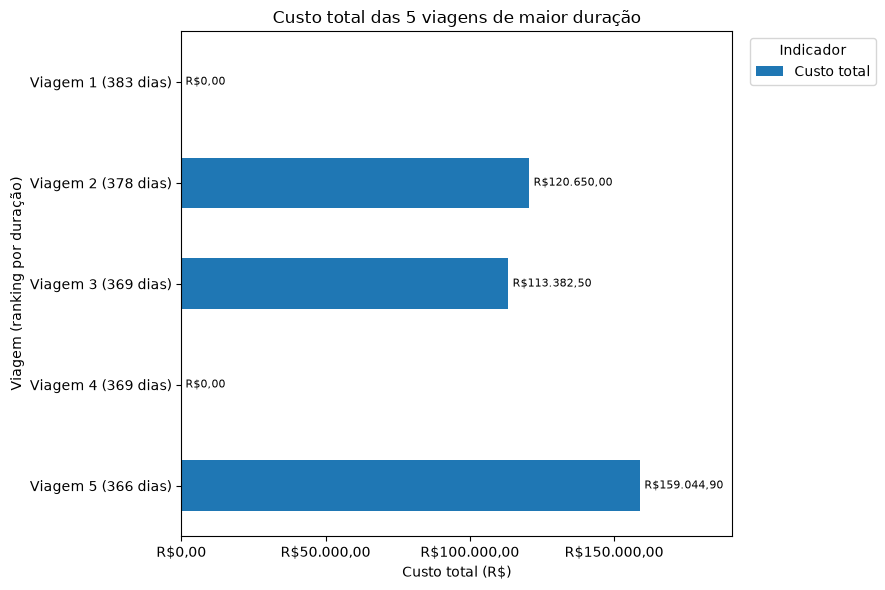

In [47]:
df_q3["rotulo"] = [
    f"Viagem {posicao} ({duracao} dias)"
    for posicao, duracao in enumerate(df_q3["duracao_dias"], start=1)
]
ax = df_q3.plot.barh(
    x="rotulo",
    y="custo_total",
    label="Custo total",
    figsize=(11, 6),
)
ax.invert_yaxis()
ax.set_title("Custo total das 5 viagens de maior duração")
ax.legend(title="Indicador", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_xlabel("Custo total (R$)")
ax.set_ylabel("Viagem (ranking por duração)")
ax.xaxis.set_major_formatter(FuncFormatter(formatar_eixo_brl))
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.margins(x=0.2)
ax.bar_label(
    ax.containers[0],
    labels=[formatar_brl(valor) for valor in df_q3["custo_total"]],
    padding=3,
    fontsize=8,
)
plt.tight_layout(rect=(0, 0, 0.82, 1))
plt.show()

# Camada Gold

A tabela e a VIEW abaixo materializam uma visão agregada por órgão. O pagamento é primeiro agregado por viagem para evitar multiplicação de valores quando há vários registros de pagamento para uma mesma viagem. Em seguida, ocorre o `JOIN` com a Silver e o `GROUP BY` por órgão.

In [8]:
sql_gold = """
DROP VIEW IF EXISTS vw_gold_uf_destino;
DROP TABLE IF EXISTS gold_uf_destino;
DROP VIEW IF EXISTS vw_gold_transporte;
DROP TABLE IF EXISTS gold_transporte;
DROP VIEW IF EXISTS vw_gold_tipo_pagamento;
DROP TABLE IF EXISTS gold_tipo_pagamento;
DROP VIEW IF EXISTS vw_gold_orgao_pagador;
DROP TABLE IF EXISTS gold_orgao_pagador;
DROP VIEW IF EXISTS vw_gold_orgao;
DROP TABLE IF EXISTS gold_orgao;

-- Agregação por órgão superior: custo das viagens e pagamentos associados.
CREATE TABLE gold_orgao AS
SELECT
    v.nome_orgao_superior AS orgao,
    COUNT(DISTINCT v.id_viagem) AS quantidade_viagens,
    ROUND(SUM(v.valor_total), 2) AS custo_total,
    ROUND(AVG(v.valor_total), 2) AS custo_medio_por_viagem,
    ROUND(COALESCE(SUM(p.total_pagamento_viagem), 0), 2) AS total_pagamentos,
    COALESCE(SUM(p.quantidade_pagamentos), 0) AS quantidade_pagamentos
FROM silver_viagem v
LEFT JOIN (
    SELECT id_viagem, SUM(valor) AS total_pagamento_viagem, COUNT(*) AS quantidade_pagamentos
    FROM silver_pagamento
    GROUP BY id_viagem
) p ON p.id_viagem = v.id_viagem
GROUP BY v.nome_orgao_superior;

CREATE INDEX idx_gold_orgao_custo ON gold_orgao(custo_total DESC);
CREATE VIEW vw_gold_orgao AS SELECT * FROM gold_orgao;

-- Órgão pagador efetivo: não confundir com órgão superior da viagem.
CREATE TABLE gold_orgao_pagador AS
SELECT
    COALESCE(NULLIF(TRIM(p.nome_orgao_pagador), ''), 'Não informado') AS orgao_pagador,
    COUNT(*) AS quantidade_pagamentos,
    COUNT(DISTINCT p.id_viagem) AS quantidade_viagens,
    ROUND(SUM(p.valor), 2) AS total_pago,
    ROUND(AVG(p.valor), 2) AS valor_medio_pagamento
FROM silver_pagamento p
JOIN silver_viagem v ON v.id_viagem = p.id_viagem
GROUP BY COALESCE(NULLIF(TRIM(p.nome_orgao_pagador), ''), 'Não informado');

CREATE INDEX idx_gold_orgao_pagador_total ON gold_orgao_pagador(total_pago DESC);
CREATE VIEW vw_gold_orgao_pagador AS SELECT * FROM gold_orgao_pagador;

-- Três agregações adicionais para responder às perguntas 4, 5 e 6 pela Gold.
DROP VIEW IF EXISTS vw_gold_tipo_pagamento;
DROP TABLE IF EXISTS gold_tipo_pagamento;
CREATE TABLE gold_tipo_pagamento AS
SELECT tipo_pagamento, COUNT(*) AS quantidade_pagamentos,
       ROUND(AVG(valor), 2) AS valor_medio
FROM silver_pagamento
WHERE NULLIF(TRIM(tipo_pagamento), '') IS NOT NULL
GROUP BY tipo_pagamento;
CREATE VIEW vw_gold_tipo_pagamento AS SELECT * FROM gold_tipo_pagamento;

DROP VIEW IF EXISTS vw_gold_transporte;
DROP TABLE IF EXISTS gold_transporte;
CREATE TABLE gold_transporte AS
SELECT TRIM(meio_transporte) AS meio_transporte, COUNT(*) AS quantidade_trechos
FROM silver_trecho
WHERE NULLIF(TRIM(meio_transporte), '') IS NOT NULL
GROUP BY TRIM(meio_transporte);
CREATE VIEW vw_gold_transporte AS SELECT * FROM gold_transporte;

DROP VIEW IF EXISTS vw_gold_uf_destino;
DROP TABLE IF EXISTS gold_uf_destino;
CREATE TABLE gold_uf_destino AS
SELECT TRIM(destino_uf) AS uf_destino, COUNT(*) AS quantidade_trechos
FROM silver_trecho
WHERE NULLIF(TRIM(destino_uf), '') IS NOT NULL
GROUP BY TRIM(destino_uf);
CREATE VIEW vw_gold_uf_destino AS SELECT * FROM gold_uf_destino;
"""
with conexao.cursor() as cursor:
    cursor.execute(sql_gold)
conexao.commit()
print("Tabelas e VIEWs Gold criadas com sucesso.")

Tabelas e VIEWs Gold criadas com sucesso.


## 5. Pergunta 4 — Qual tipo de pagamento apresenta o maior valor médio?

A tabela e o gráfico exibem todos os tipos de pagamento, ordenados pelo valor médio. A primeira linha corresponde ao maior valor.

In [50]:
sql_q4 = """
SELECT tipo_pagamento, quantidade_pagamentos, valor_medio
FROM vw_gold_tipo_pagamento
ORDER BY valor_medio DESC, tipo_pagamento;
"""
df_q4 = pd.read_sql_query(sql_q4, conexao)
df_q4.assign(valor_medio=df_q4["valor_medio"].map(formatar_brl))

C:\Users\John\AppData\Local\Temp\ipykernel_21892\1047637099.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q4 = pd.read_sql_query(sql_q4, conexao)


,tipo_pagamento,quantidade_pagamentos,valor_medio
0,DIÁRIAS,401463,"R$2.078,28"
1,PASSAGEM,188985,"R$1.878,34"
2,Serviço correlato: seguro,4894,"R$447,51"
3,RESTITUIÇÃO,11574,"R$245,70"


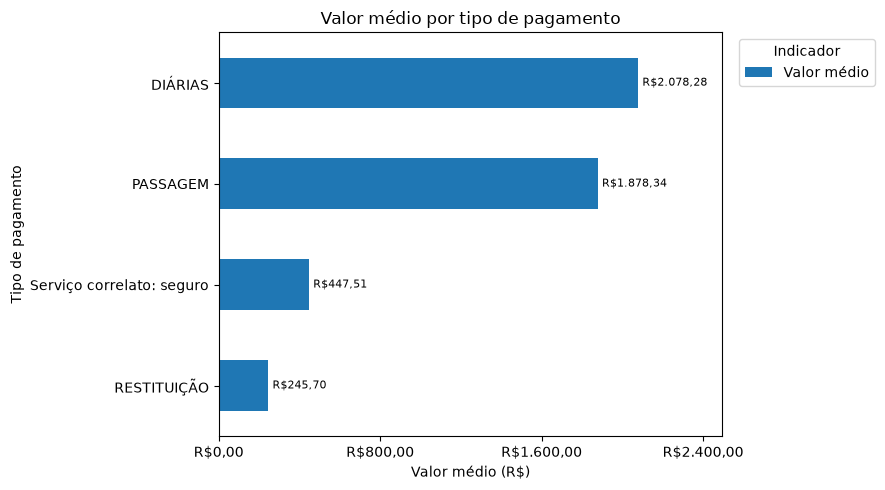

In [51]:
ax = df_q4.plot.barh(
    x="tipo_pagamento",
    y="valor_medio",
    label="Valor médio",
    figsize=(11, 5),
)
ax.invert_yaxis()
ax.set_title("Valor médio por tipo de pagamento")
ax.legend(title="Indicador", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_xlabel("Valor médio (R$)")
ax.set_ylabel("Tipo de pagamento")
ax.xaxis.set_major_formatter(FuncFormatter(formatar_eixo_brl))
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.margins(x=0.2)
ax.bar_label(
    ax.containers[0],
    labels=[formatar_brl(valor) for valor in df_q4["valor_medio"]],
    padding=3,
    fontsize=8,
)
plt.tight_layout(rect=(0, 0, 0.82, 1))
plt.show()

## 6. Pergunta 5 — Qual é o meio de transporte mais usado nos trechos?

A tabela e o gráfico exibem todos os meios de transporte, ordenados do mais frequente ao menos frequente pela VIEW agregada `vw_gold_transporte`.

In [54]:
sql_q5 = """
SELECT meio_transporte, quantidade_trechos
FROM vw_gold_transporte
ORDER BY quantidade_trechos DESC, meio_transporte;
"""
df_q5 = pd.read_sql_query(sql_q5, conexao)
df_q5

C:\Users\John\AppData\Local\Temp\ipykernel_21892\3149244576.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q5 = pd.read_sql_query(sql_q5, conexao)


,meio_transporte,quantidade_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


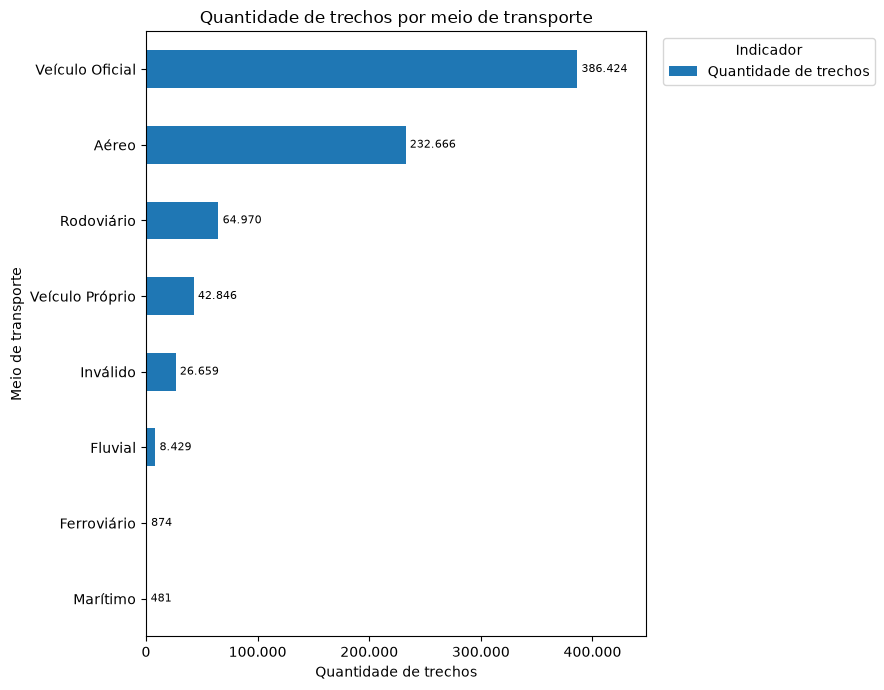

In [55]:
ax = df_q5.plot.barh(
    x="meio_transporte",
    y="quantidade_trechos",
    label="Quantidade de trechos",
    figsize=(11, 7),
)
ax.invert_yaxis()
ax.set_title("Quantidade de trechos por meio de transporte")
ax.legend(title="Indicador", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_xlabel("Quantidade de trechos")
ax.set_ylabel("Meio de transporte")
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda valor, _: f"{valor:,.0f}".replace(",", "."))
)
ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
ax.margins(x=0.16)
ax.bar_label(
    ax.containers[0],
    labels=[f"{int(valor):,}".replace(",", ".") for valor in df_q5["quantidade_trechos"]],
    padding=3,
    fontsize=8,
)
plt.tight_layout(rect=(0, 0, 0.82, 1))
plt.show()

## 7. Pergunta 6 — Qual UF de destino aparece em mais trechos?

A resposta utiliza a VIEW agregada `vw_gold_uf_destino`, criada na camada Gold por meio de `GROUP BY`.

In [42]:
sql_q6 = """
SELECT uf_destino, quantidade_trechos
FROM vw_gold_uf_destino
ORDER BY quantidade_trechos DESC, uf_destino
LIMIT 5;
"""
df_q6 = pd.read_sql_query(sql_q6, conexao)
df_q6

C:\Users\John\AppData\Local\Temp\ipykernel_21892\2937169179.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q6 = pd.read_sql_query(sql_q6, conexao)


,uf_destino,quantidade_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603


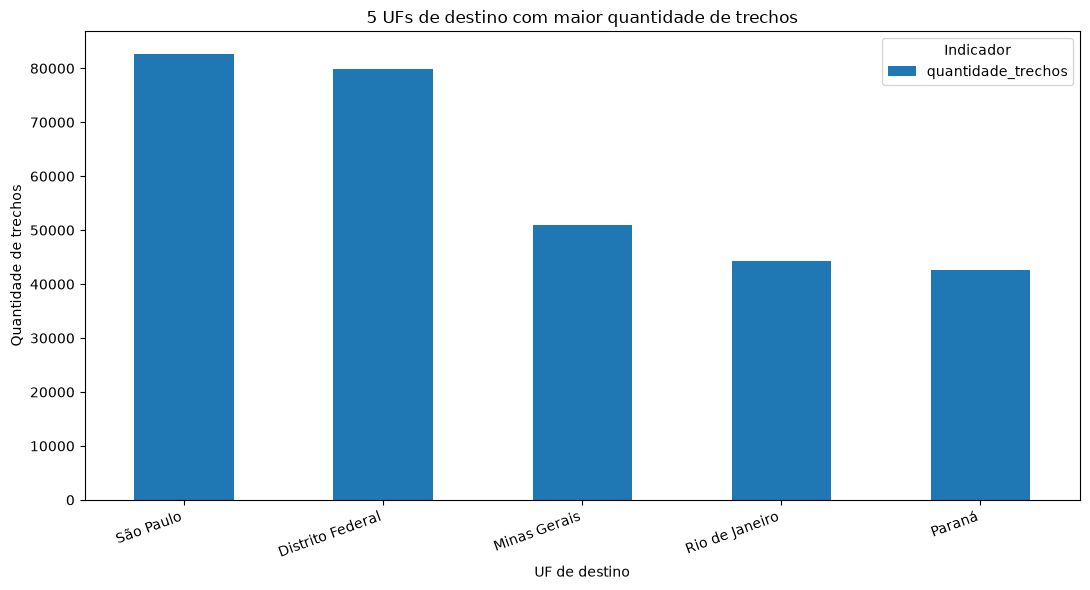

In [43]:
ax = df_q6.plot.bar(x="uf_destino", y="quantidade_trechos", legend=True, figsize=(11, 6))
ax.set_title("5 UFs de destino com maior quantidade de trechos")
ax.legend(title="Indicador")
ax.set_xlabel("UF de destino")
ax.set_ylabel("Quantidade de trechos")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 8. Pergunta 7 — Qual órgão pagou mais no total?

A resposta utiliza a agregação `gold_orgao_pagador`, que soma os valores de `silver_pagamento` por `nome_orgao_pagador`. Isso distingue o órgão pagador efetivo do órgão superior responsável pela viagem. A consulta é feita pela VIEW Gold criada com `JOIN` e `GROUP BY`.


In [27]:
sql_q7 = """
SELECT
    orgao_pagador AS orgao,
    quantidade_viagens,
    quantidade_pagamentos,
    total_pago
FROM vw_gold_orgao_pagador
ORDER BY total_pago DESC, orgao_pagador
LIMIT 1;
"""
df_q7 = pd.read_sql_query(sql_q7, conexao)
df_q7.assign(total_pago=df_q7["total_pago"].map(formatar_brl))

C:\Users\John\AppData\Local\Temp\ipykernel_21892\1017131037.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q7 = pd.read_sql_query(sql_q7, conexao)


,orgao,quantidade_viagens,quantidade_pagamentos,total_pago
0,Fundo Nacional de Segurança Pública,24116,79816,"R$278.481.047,89"


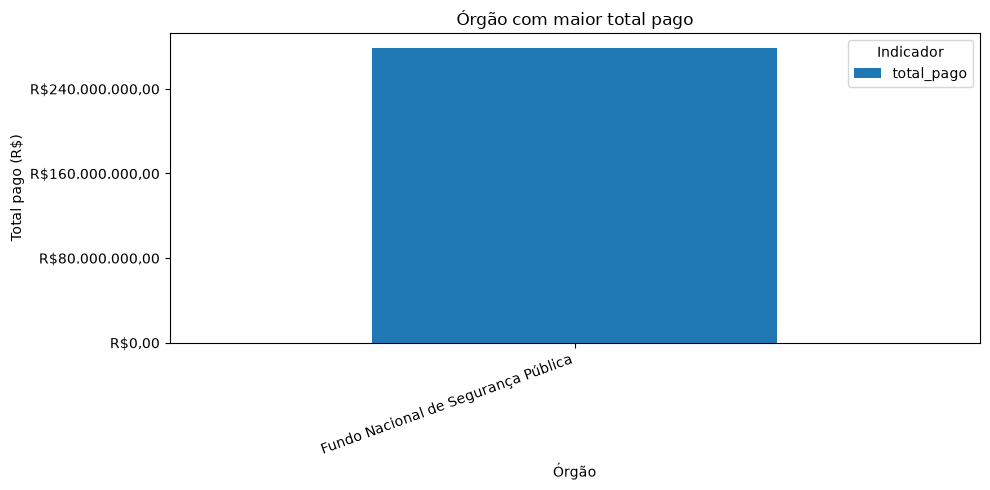

In [37]:
ax = df_q7.plot.bar(x="orgao", y="total_pago", legend=True, figsize=(10, 5))
ax.set_title("Órgão com maior total pago")
ax.legend(title="Indicador")
ax.set_xlabel("Órgão")
ax.set_ylabel("Total pago (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_eixo_brl))
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 9. Visão consolidada da Gold

A consulta abaixo permite conferir as principais métricas agregadas por órgão.

In [28]:
df_gold = pd.read_sql_query("""
SELECT *
FROM vw_gold_orgao
ORDER BY custo_total DESC
LIMIT 10;
""", conexao)
df_gold.assign(
    custo_total=df_gold["custo_total"].map(formatar_brl),
    custo_medio_por_viagem=df_gold["custo_medio_por_viagem"].map(formatar_brl),
    total_pagamentos=df_gold["total_pagamentos"].map(formatar_brl),
)

C:\Users\John\AppData\Local\Temp\ipykernel_21892\198147664.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_gold = pd.read_sql_query("""


,orgao,quantidade_viagens,custo_total,custo_medio_por_viagem,total_pagamentos,quantidade_pagamentos
0,Ministério da Justiça e Segurança Pública,75742,"R$486.933.121,65","R$6.428,84","R$488.831.110,61",175814.0
1,Ministério da Defesa,61912,"R$156.070.304,49","R$2.520,84","R$156.549.767,91",93574.0
2,Ministério da Educação,65295,"R$111.291.349,34","R$1.704,44","R$111.897.434,35",93340.0
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"R$49.697.710,16","R$2.560,02","R$50.123.043,80",26394.0
4,Ministério da Previdência Social,8190,"R$40.417.309,06","R$4.934,96","R$40.659.494,63",20106.0
5,Ministério da Saúde,8672,"R$39.049.825,61","R$4.502,98","R$39.517.918,03",18914.0
6,Ministério da Fazenda,11854,"R$32.474.392,19","R$2.739,53","R$32.666.017,41",23613.0
7,Ministério dos Povos Indígenas,5101,"R$26.286.915,37","R$5.153,29","R$26.441.142,20",10618.0
8,Ministério das Relações Exteriores,2014,"R$25.533.548,96","R$12.678,03","R$25.724.337,16",3757.0
9,Ministério do Desenvolvimento Agrário e Agricu...,8581,"R$21.998.422,21","R$2.563,62","R$22.171.683,47",13247.0


## 10. Interpretação dos resultados e fechamento

As consultas executadas no PostgreSQL produziram os seguintes resultados:

- **Concentração de custos:** o Ministério da Justiça e Segurança Pública lidera com **R$ 486.933.121,65** em 75.742 viagens. Em segundo lugar está o Ministério da Defesa, com **R$ 156.070.304,49**; a diferença é de **R$ 330.862.817,16**, e o custo do líder é cerca de 3,12 vezes maior. Completam os cinco primeiros o Ministério da Educação (**R$ 111.291.349,34**), o Ministério do Meio Ambiente e Mudança do Clima (**R$ 49.697.710,16**) e o Ministério da Previdência Social (**R$ 40.417.309,06**). Há uma concentração acentuada no primeiro colocado.
- **Destinos:** os três maiores custos médios retornados foram Tejupá/SP (**R$ 115.175,00**), Chavantes/SP (**R$ 114.557,01**) e Teolândia/BA (**R$ 109.322,50**). Cada destino aparece associado a **uma única viagem** na consulta. Portanto, esses valores refletem casos isolados, não um padrão recorrente de alto custo; devem ser interpretados com cautela.
- **Duração:** a viagem de maior duração tem **383 dias**, de **13/01/2025 a 31/01/2026**, para Mogi Mirim/SP, com custo total registrado de **R$ 0,00**. Como atravessa o ano seguinte e tem custo zero, é um caso atípico que merece conferência nos dados de origem.
- **Pagamentos:** o resultado disponível mostra **DIÁRIAS** como o tipo de pagamento com maior valor médio, com **401.463 pagamentos** e média de **R$ 2.078,28**. A consulta usa `LIMIT 1`, portanto exibe apenas o primeiro colocado; a agregação Gold contém outras categorias. Já o maior total pago por órgão pagador efetivo pertence ao **Fundo Nacional de Segurança Pública**: **R$ 278.481.047,89**, em **79.816 pagamentos** associados a **24.116 viagens**. Valor médio por tipo e total pago por órgão são métricas diferentes e não devem ser confundidos.
- **Mobilidade:** **Veículo Oficial** foi o meio de transporte mais frequente, com **386.424 trechos**. São Paulo lidera a distribuição por UF de destino, com **82.722 trechos**, seguido pelo Distrito Federal (79.962), Minas Gerais (50.965), Rio de Janeiro (44.197) e Paraná (42.603). Assim, o transporte oficial predomina, e São Paulo aparece ligeiramente à frente do Distrito Federal entre os destinos mais frequentes.

No aspecto técnico, a camada **Raw** preserva os quatro CSVs sem tipagem nem tratamento de conteúdo. A camada **Silver** converte datas e valores, calcula `valor_total` e `duracao_dias` e aplica chaves primárias, estrangeiras e constraints. A camada **Gold** consolida indicadores por órgão superior, órgão pagador, tipo de pagamento, meio de transporte e UF de destino; agrega dados relacionados com `JOIN` e `GROUP BY` e disponibiliza tabelas e VIEWs para reutilização.

As sete perguntas de negócio foram respondidas com consultas SQL, tabelas e gráficos no notebook. Os achados mais importantes são a concentração do custo no Ministério da Justiça e Segurança Pública, os destinos de maior custo médio baseados em apenas um caso cada, e a necessidade de revisar a viagem atípica de 383 dias com custo zero.

In [52]:
conexao.close()
print("Conexão encerrada.")

Conexão encerrada.
